# Child survival: who is on track for 2030, and what separates countries that do well?

**Question.** Which countries will miss the global target for under-five mortality, how many children's lives are at stake, and which measurable conditions (immunisation, water, sanitation, income, fertility, health spending) are most strongly associated with child survival?

**Why it matters.** Almost five million children still die each year before their fifth birthday, most from causes that are preventable or treatable. Sustainable Development Goal 3.2 commits every country to an under-five mortality rate of **25 or fewer deaths per 1,000 live births by 2030**. Knowing who is off track, by how much, and which countries are achieving more than their income would predict helps direct attention and money.

**Data.** [World Development Indicators](https://databank.worldbank.org/source/world-development-indicators) from the World Bank, downloaded through its public API. Mortality estimates come from the UN Inter-agency Group for Child Mortality Estimation. Sixteen indicators, every country, 2000 onwards.

**What this notebook does**

1. Downloads and assembles a country-year panel
2. Describes progress since 2000 and where deaths are concentrated
3. Projects each country to 2030 and classifies it against the SDG target
4. Models under-five mortality from development indicators, validated on countries the model has not seen
5. Identifies countries doing better or worse than their circumstances predict
6. Exports the model and data for the live dashboard

## 1. Setup

In [1]:
import io
import json
import warnings
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path("..")
RAW = ROOT / "data" / "raw"
APP = ROOT / "docs" / "data"
RAW.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#77766f"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "axes.axisbelow": True, "font.size": 10,
})

## 2. Download the indicators

Each indicator is one small zip file from the World Bank API. They are downloaded in parallel, retried if the API is slow, and cached.

In [2]:
INDICATORS = {
    "SH.DYN.MORT": "u5mr",
    "SH.DTH.MORT": "u5_deaths",
    "SP.POP.TOTL": "population",
    "NY.GDP.PCAP.PP.KD": "gdp_per_capita",
    "SH.IMM.IDPT": "dpt_immunisation",
    "SH.IMM.MEAS": "measles_immunisation",
    "SH.H2O.BASW.ZS": "basic_water",
    "SH.STA.BASS.ZS": "basic_sanitation",
    "SH.XPD.CHEX.PC.CD": "health_spending",
    "SP.ADO.TFRT": "adolescent_fertility",
    "SP.DYN.TFRT.IN": "fertility",
    "EG.ELC.ACCS.ZS": "electricity",
    "SP.URB.TOTL.IN.ZS": "urban",
    "SN.ITK.DEFC.ZS": "undernourishment",
    "SH.STA.BRTC.ZS": "skilled_birth_attendance",
    "SH.MED.PHYS.ZS": "physicians",
}


def fetch(code):
    path = RAW / f"{code}.zip"
    if not path.exists():
        url = f"https://api.worldbank.org/v2/en/indicator/{code}?downloadformat=csv"
        for attempt in range(4):
            try:
                response = requests.get(url, timeout=60)
                response.raise_for_status()
                path.write_bytes(response.content)
                break
            except requests.RequestException:
                if attempt == 3:
                    raise
    archive = zipfile.ZipFile(path)
    data_name = next(n for n in archive.namelist() if n.startswith("API_"))
    meta_name = next(n for n in archive.namelist() if n.startswith("Metadata_Country"))
    data = pd.read_csv(archive.open(data_name), skiprows=4)
    meta = pd.read_csv(archive.open(meta_name))
    return code, data, meta


with ThreadPoolExecutor(4) as pool:
    downloads = list(pool.map(fetch, INDICATORS))

meta = downloads[0][2][["Country Code", "Region", "IncomeGroup"]].dropna(subset=["Region"])
frames = []
for code, data, _ in downloads:
    years = [c for c in data.columns if c.isdigit() and int(c) >= 2000]
    long = data.melt(id_vars=["Country Name", "Country Code"], value_vars=years, var_name="year", value_name=INDICATORS[code])
    frames.append(long.set_index(["Country Code", "Country Name", "year"]))
wide = pd.concat(frames, axis=1).reset_index()
wide["year"] = wide["year"].astype(int)

world = wide[wide["Country Code"] == "WLD"].set_index("year")
panel = wide.merge(meta, on="Country Code").rename(columns={"Country Code": "iso3", "Country Name": "country", "Region": "region", "IncomeGroup": "income"})
panel = panel.dropna(subset=["u5mr"])
LAST = int(panel["year"].max())
print(f"{panel['iso3'].nunique()} countries, {panel['year'].min()} to {LAST}, {len(panel):,} country-years with a mortality estimate")
panel.head(3)

196 countries, 2000 to 2024, 4,900 country-years with a mortality estimate


,iso3,country,year,u5mr,u5_deaths,population,gdp_per_capita,dpt_immunisation,measles_immunisation,basic_water,...,health_spending,adolescent_fertility,fertility,electricity,urban,undernourishment,skilled_birth_attendance,physicians,region,income
1,AFG,Afghanistan,2000,131.7,131354.0,20130327.0,1617.826475,24.0,27.0,29.730966,...,NaN,154.310,7.566,4.4,18.558200,NaN,12.4,NaN,Middle East & North Africa,Low income
2,AGO,Angola,2000,185.0,132456.0,16194869.0,6794.530211,31.0,41.0,37.842237,...,13.159986,147.693,6.639,24.2,50.507065,NaN,NaN,NaN,Sub-Saharan Africa,Lower middle income
3,ALB,Albania,2000,27.0,1629.0,3089027.0,6581.989092,97.0,95.0,86.397042,...,65.476746,14.743,2.217,99.4,41.613583,NaN,99.1,1.366,Europe & Central Asia,Upper middle income


The World Bank file mixes countries with regional aggregates such as "Sub-Saharan Africa" and "World". Only rows with a region assigned in the country metadata are real countries, so the merge with the metadata removes the aggregates. The world aggregate is kept separately for the headline trend.

In [3]:
coverage = panel[list(INDICATORS.values())].notna().mean().mul(100).round(0).sort_values()
print("Share of country-years with a value (%):")
print(coverage.to_string())

Share of country-years with a value (%):
skilled_birth_attendance     46.0
physicians                   58.0
undernourishment             80.0
health_spending              93.0
gdp_per_capita               95.0
basic_sanitation             96.0
basic_water                  97.0
measles_immunisation         98.0
dpt_immunisation             98.0
electricity                  99.0
population                  100.0
u5mr                        100.0
u5_deaths                   100.0
adolescent_fertility        100.0
fertility                   100.0
urban                       100.0


Coverage varies. Mortality, population, fertility and immunisation are nearly complete. Skilled birth attendance and physician density come from occasional surveys and are missing for most years. They are kept, because the gradient boosted model can handle missing values directly, but they will carry less weight.

## 3. Progress since 2000

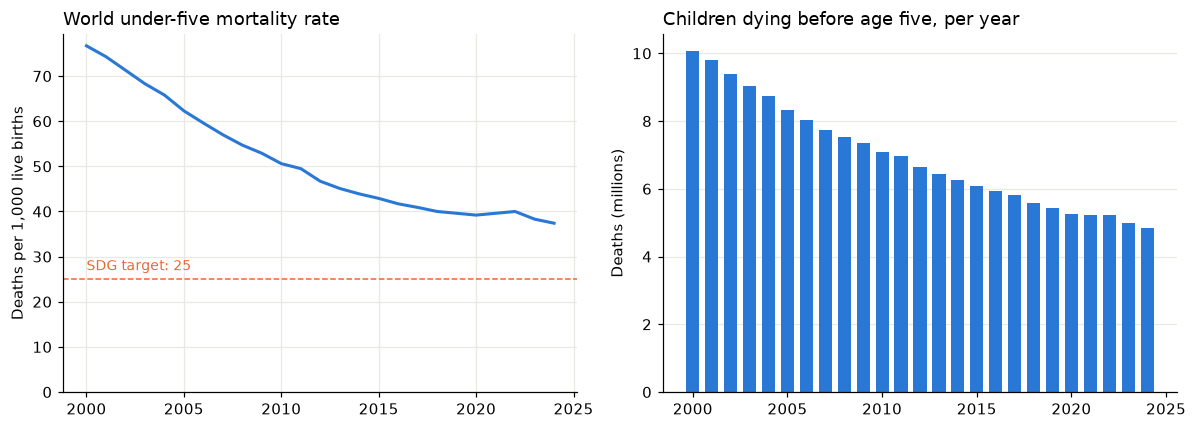

World rate: 77 per 1,000 in 2000, 37 in 2024 (-51%)
Deaths:     10.1 million in 2000, 4.9 million in 2024


In [4]:
w = world[["u5mr", "u5_deaths"]].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(w.index, w["u5mr"], color=BLUE, lw=2)
axes[0].axhline(25, color=ORANGE, ls="--", lw=1)
axes[0].text(w.index.min(), 27, "SDG target: 25", color=ORANGE, fontsize=9)
axes[0].set_ylim(0)
axes[0].set_ylabel("Deaths per 1,000 live births")
axes[0].set_title("World under-five mortality rate", loc="left")
axes[1].bar(w.index, w["u5_deaths"] / 1e6, color=BLUE, width=0.7)
axes[1].set_ylabel("Deaths (millions)")
axes[1].set_title("Children dying before age five, per year", loc="left")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

first_year, last_year = int(w.index.min()), int(w.index.max())
print(f"World rate: {w.loc[first_year, 'u5mr']:.0f} per 1,000 in {first_year}, {w.loc[last_year, 'u5mr']:.0f} in {last_year} ({w.loc[last_year, 'u5mr'] / w.loc[first_year, 'u5mr'] - 1:+.0%})")
print(f"Deaths:     {w.loc[first_year, 'u5_deaths'] / 1e6:.1f} million in {first_year}, {w.loc[last_year, 'u5_deaths'] / 1e6:.1f} million in {last_year}")

The world has roughly halved child mortality since 2000, one of the largest improvements in human welfare on record. But the world average is still above the target that every individual country is supposed to reach by 2030, and progress is very uneven.

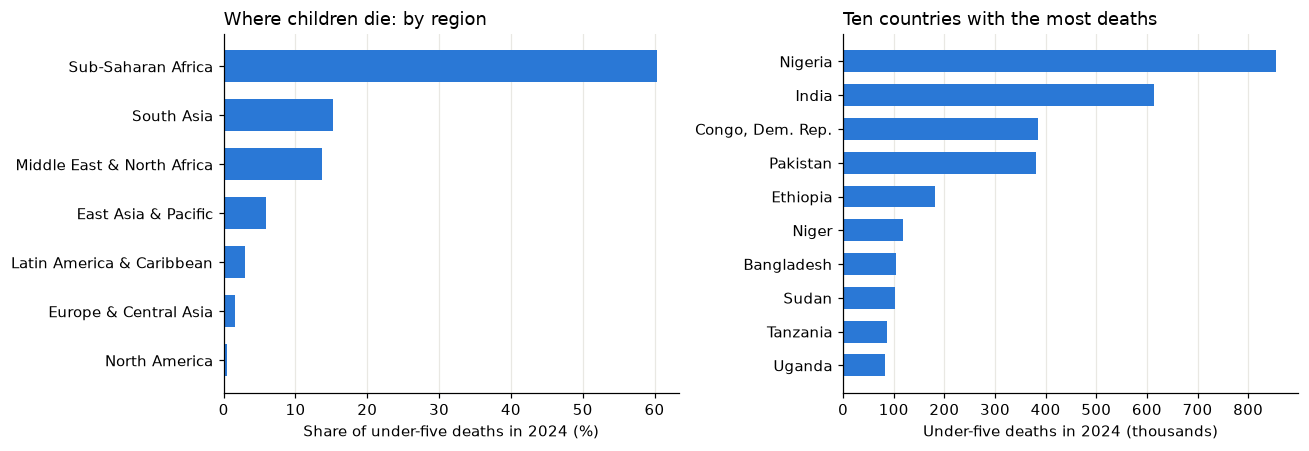

                               deaths  countries  median_rate  share_of_deaths
region                                                                        
Sub-Saharan Africa          2931098.0         48        48.90            0.603
South Asia                   736800.0          6        21.15            0.152
Middle East & North Africa   664233.0         23        12.90            0.137
East Asia & Pacific          282953.0         30        17.20            0.058
Latin America & Caribbean    142632.0         35        13.10            0.029
Europe & Central Asia         74443.0         52         3.90            0.015
North America                 25634.0          2         5.95            0.005

The ten countries above account for 60% of all under-five deaths.


In [5]:
latest = panel[panel["year"] == LAST]
by_region = latest.groupby("region").agg(deaths=("u5_deaths", "sum"), countries=("iso3", "size"), median_rate=("u5mr", "median")).sort_values("deaths", ascending=False)
by_region["share_of_deaths"] = by_region["deaths"] / by_region["deaths"].sum()
top_countries = latest.nlargest(10, "u5_deaths")[["country", "u5_deaths", "u5mr"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(by_region.index[::-1], by_region["share_of_deaths"][::-1] * 100, color=BLUE, height=0.65)
axes[0].set_xlabel(f"Share of under-five deaths in {LAST} (%)")
axes[0].set_title("Where children die: by region", loc="left")
axes[0].grid(axis="y", visible=False)
axes[1].barh(top_countries["country"][::-1], top_countries["u5_deaths"][::-1] / 1000, color=BLUE, height=0.65)
axes[1].set_xlabel(f"Under-five deaths in {LAST} (thousands)")
axes[1].set_title("Ten countries with the most deaths", loc="left")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(by_region.round(3).to_string())
print()
print(f"The ten countries above account for {top_countries['u5_deaths'].sum() / latest['u5_deaths'].sum():.0%} of all under-five deaths.")

Deaths are heavily concentrated. Sub-Saharan Africa alone accounts for about 60 percent, and ten populous countries account for 60 percent of the global total. (The World Bank's current regional grouping places Afghanistan and Pakistan with the Middle East and North Africa, which is why that region's share is larger than older publications show.) Rates matter for fairness, but counts matter for impact: a modest improvement in a very large country saves more children than a large improvement in a small one.

## 4. Who is on track for 2030?

For each country, fit a straight line to the logarithm of its mortality rate over the last ten years. The slope is the **annual rate of reduction** (ARR), the standard measure used by UNICEF. Projecting that trend forward to 2030 gives an estimate of where each country will be if nothing changes.

Each country is then classified:

* **Target met**: already at or below 25
* **On track**: above 25 now, projected to reach 25 by 2030
* **Off track**: projected to still be above 25 in 2030

For off-track countries, the **required ARR** is the pace they would need from now on to reach 25 by 2030.

In [6]:
WINDOW = 10
rows = []
for iso3, group in panel[panel["year"] > LAST - WINDOW].groupby("iso3"):
    group = group.sort_values("year")
    if len(group) < 5:
        continue
    slope, intercept = np.polyfit(group["year"], np.log(group["u5mr"]), 1)
    current = float(group["u5mr"].iloc[-1])
    projected = current * float(np.exp(slope * (2030 - LAST)))
    status = "Target met" if current <= 25 else ("On track" if projected <= 25 else "Off track")
    required = float(np.log(current / 25) / (2030 - LAST)) if current > 25 else 0.0
    births_proxy = float(group["u5_deaths"].iloc[-1] / current * 1000) if current > 0 and pd.notna(group["u5_deaths"].iloc[-1]) else np.nan
    excess = max(projected - 25, 0) / 1000 * births_proxy if pd.notna(births_proxy) else np.nan
    rows.append({"iso3": iso3, "country": group["country"].iloc[-1], "region": group["region"].iloc[-1], "income": group["income"].iloc[-1],
                 "u5mr": current, "arr": -slope, "projected_2030": projected, "required_arr": required, "status": status,
                 "deaths": float(group["u5_deaths"].iloc[-1]), "excess_deaths_2030": excess})
sdg = pd.DataFrame(rows)
counts = sdg["status"].value_counts()
print(counts.to_string())
print()
off = sdg[sdg["status"] == "Off track"].sort_values("projected_2030", ascending=False)
print(f"Off-track countries by region:\n{off['region'].value_counts().to_string()}")
print()
print(f"Median annual rate of reduction among off-track countries: {off['arr'].median():.1%}; median rate they need: {off['required_arr'].median():.1%}")
print(f"Children who would die in 2030 above the target level in off-track countries, if trends continue: {off['excess_deaths_2030'].sum():,.0f}")

status
Target met    130
Off track      61
On track        5

Off-track countries by region:
region
Sub-Saharan Africa            44
East Asia & Pacific            6
Middle East & North Africa     5
Latin America & Caribbean      3
Europe & Central Asia          2
South Asia                     1

Median annual rate of reduction among off-track countries: 2.6%; median rate they need: 11.1%
Children who would die in 2030 above the target level in off-track countries, if trends continue: 1,865,021


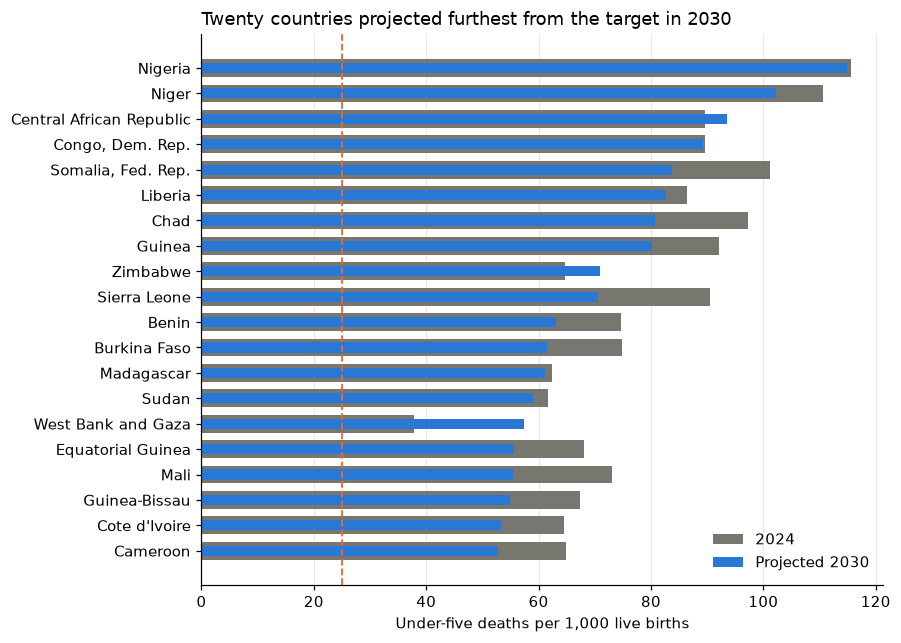

,country,region,u5mr,arr,projected_2030,required_arr
125,Nigeria,Sub-Saharan Africa,115.6,0.001,114.835,0.255
124,Niger,Sub-Saharan Africa,110.7,0.013,102.323,0.248
28,Central African Republic,Sub-Saharan Africa,89.7,-0.007,93.597,0.213
35,"Congo, Dem. Rep.",Sub-Saharan Africa,89.7,0.001,89.262,0.213
156,"Somalia, Fed. Rep.",Sub-Saharan Africa,101.1,0.032,83.674,0.233
97,Liberia,Sub-Saharan Africa,86.4,0.007,82.702,0.207
168,Chad,Sub-Saharan Africa,97.3,0.031,80.768,0.226
64,Guinea,Sub-Saharan Africa,92.1,0.023,80.161,0.217
195,Zimbabwe,Sub-Saharan Africa,64.7,-0.015,70.952,0.158
153,Sierra Leone,Sub-Saharan Africa,90.5,0.042,70.549,0.214


In [7]:
show = off.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(show["country"], show["u5mr"], color=GREY, height=0.7, label=f"{LAST}")
ax.barh(show["country"], show["projected_2030"], color=BLUE, height=0.4, label="Projected 2030")
ax.axvline(25, color=ORANGE, ls="--", lw=1.2)
ax.set_xlabel("Under-five deaths per 1,000 live births")
ax.set_title("Twenty countries projected furthest from the target in 2030", loc="left")
ax.legend(frameon=False)
ax.grid(axis="y", visible=False)
plt.show()
off[["country", "region", "u5mr", "arr", "projected_2030", "required_arr"]].head(10).round(3)

Of 61 off-track countries, 44 are in Sub-Saharan Africa. Most are reducing mortality, but at a fraction of the pace they would need: a median of 2.6 percent a year against the 11 percent a year required. The gap between the median current pace and the median required pace, printed above, is the size of the acceleration needed.

The final figure is an estimate of the annual death toll in 2030 that lies above the target level in those countries if current trends continue. It assumes the number of births stays at its current level, so it is an order-of-magnitude figure, not a forecast.

### How fragile is the classification?

A single projected number hides two sources of doubt, so both are checked here.

**1. The choice of trend window.** Ten years is a convention, not a law. A country whose progress has recently sped up or stalled will project differently on a 5-year or a 15-year trend. The classification is repeated with all three windows.

**2. Countries near the line.** A country projected at 26 is labelled off track and one projected at 24 is labelled on track, but the data cannot really tell those apart. Any country that is above the target today and projected to land between 20 and 30 per 1,000 in 2030 is flagged as **too close to call**.

In [8]:
def classify(window):
    out = {}
    for iso3, group in panel[panel["year"] > LAST - window].groupby("iso3"):
        group = group.sort_values("year")
        if len(group) < 5:
            continue
        slope = np.polyfit(group["year"], np.log(group["u5mr"]), 1)[0]
        current = float(group["u5mr"].iloc[-1])
        projected = current * float(np.exp(slope * (2030 - LAST)))
        out[iso3] = {"projected": projected, "status": "Target met" if current <= 25 else ("On track" if projected <= 25 else "Off track")}
    return pd.DataFrame(out).T


by_window = {window: classify(window) for window in (5, 10, 15)}
sensitivity = pd.DataFrame({f"{window}-year trend": by_window[window]["status"].value_counts() for window in by_window})
sensitivity = sensitivity.reindex(["Target met", "On track", "Off track"]).fillna(0).astype(int)
sensitivity.index.name = "Status"

for window in (5, 15):
    sdg[f"projected_{window}y"] = sdg["iso3"].map(by_window[window]["projected"]).astype(float)
    sdg[f"status_{window}y"] = sdg["iso3"].map(by_window[window]["status"])
sdg["borderline"] = (sdg["u5mr"] > 25) & sdg["projected_2030"].between(20, 30)

changed = sdg[(sdg["status"] != sdg["status_5y"]) | (sdg["status"] != sdg["status_15y"])]
borderline = sdg[sdg["borderline"]].sort_values("projected_2030")
print("Countries whose status changes with the trend window:")
print(changed[["country", "u5mr", "projected_5y", "projected_2030", "projected_15y", "status_5y", "status", "status_15y"]].round(1).to_string(index=False))
print()
print(f"{len(borderline)} countries are too close to call (above 25 today, projected between 20 and 30 in 2030):")
print(borderline[["country", "u5mr", "projected_5y", "projected_2030", "projected_15y", "status"]].round(1).to_string(index=False))
sensitivity

Countries whose status changes with the trend window:
    country  u5mr  projected_5y  projected_2030  projected_15y status_5y    status status_15y
 Bangladesh  30.5          29.3            26.1           24.6 Off track Off track   On track
Philippines  26.5          24.3            25.8           25.7  On track Off track  Off track

14 countries are too close to call (above 25 today, projected between 20 and 30 in 2030):
           country  u5mr  projected_5y  projected_2030  projected_15y    status
            Guyana  25.2          20.8            20.9           21.2  On track
  Marshall Islands  26.7          22.1            22.2           22.6  On track
           Lao PDR  29.4          22.8            22.3           21.9  On track
       Philippines  26.5          24.3            25.8           25.7 Off track
        Tajikistan  28.1          25.4            25.9           25.1 Off track
        Bangladesh  30.5          29.3            26.1           24.6 Off track
             

,5-year trend,10-year trend,15-year trend
Status,,,
Target met,130,130,130
On track,6,5,6
Off track,60,61,60


The overall picture does not depend on the window: the number of off-track countries is 60 or 61 whichever trend is used. What does move is the label of individual countries near the line. The Philippines is on track on its 5-year trend and Bangladesh on its 15-year trend, and both are off track on the 10-year trend used above. For every country in the too-close-to-call list, "on track" or "off track" should be read as "within a few points of the target either way".

One source of uncertainty is not captured at all. The mortality figures are themselves estimates produced by the UN Inter-agency Group for Child Mortality Estimation, which publishes an uncertainty range around each one. Those ranges are wide for countries without complete birth and death registration, and they are not carried through into these projections. A full treatment would project the lower and upper estimates as well as the central one.

## 5. What is associated with child survival?

### Setting up the model

The target is the **logarithm of the under-five mortality rate**. Mortality spans two orders of magnitude across countries (from about 2 to over 100 per 1,000), and the log scale treats a halving the same wherever it happens.

Features are development indicators that plausibly affect child survival. Income and health spending are log-transformed because their effect is proportional: going from 1,000 to 2,000 dollars matters far more than going from 50,000 to 51,000.

### Validation: can the model describe a country it has never seen?

Rows from the same country in different years are near-duplicates. A random split would let the model memorise each country and report a flattering score. Instead, **grouped cross-validation** holds out entire countries: the model is trained on four fifths of countries and must predict every year of the remaining fifth. This tests whether the relationships generalise across countries, which is the real question.

### Three models

1. **Income only**: a straight line on log GDP per capita. The classic finding (the Preston curve) is that richer countries have healthier children. Anything else must beat this.
2. **Ridge regression** on all indicators, with missing values filled by the median.
3. **Gradient boosted trees** with **monotonic constraints**: the model is only allowed to learn that more immunisation, water, sanitation, income, electricity, skilled birth attendance and doctors go with *lower* mortality, and that higher fertility and undernourishment go with *higher* mortality. This encodes established public health knowledge and stops the model learning nonsense from noisy data.

In [9]:
model_data = panel.copy()
model_data["log_gdp"] = np.log(model_data["gdp_per_capita"])
model_data["log_health_spending"] = np.log(model_data["health_spending"])
model_data["y"] = np.log(model_data["u5mr"])

FEATURES = ["log_gdp", "log_health_spending", "dpt_immunisation", "measles_immunisation", "basic_water", "basic_sanitation",
            "electricity", "urban", "fertility", "adolescent_fertility", "undernourishment", "skilled_birth_attendance", "physicians"]
MONOTONE = {"log_gdp": -1, "log_health_spending": -1, "dpt_immunisation": -1, "measles_immunisation": -1, "basic_water": -1,
            "basic_sanitation": -1, "electricity": -1, "urban": 0, "fertility": 1, "adolescent_fertility": 1, "undernourishment": 1,
            "skilled_birth_attendance": -1, "physicians": -1}
model_data = model_data[model_data[FEATURES].notna().sum(axis=1) >= 6].reset_index(drop=True)
X, y, groups = model_data[FEATURES], model_data["y"], model_data["iso3"]
print(f"{len(model_data):,} country-years from {groups.nunique()} countries")


def make_gbm():
    return xgb.XGBRegressor(n_estimators=400, learning_rate=0.04, max_depth=4, min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                            reg_lambda=3.0, monotone_constraints="(" + ",".join(str(MONOTONE[f]) for f in FEATURES) + ")",
                            random_state=SEED, n_jobs=4)


candidates = {
    "Income only": lambda: make_pipeline(SimpleImputer(strategy="median"), LinearRegression()),
    "Ridge, all indicators": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Gradient boosting, monotonic": make_gbm,
}
oof = {name: np.zeros(len(y)) for name in candidates}
for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups):
    for name, build in candidates.items():
        columns = ["log_gdp"] if name == "Income only" else FEATURES
        model = build().fit(X.iloc[train_idx][columns], y.iloc[train_idx])
        oof[name][test_idx] = model.predict(X.iloc[test_idx][columns])

rows = []
for name, pred in oof.items():
    rows.append({"model": name, "R squared (log scale)": r2_score(y, pred),
                 "Median error (%)": float(np.median(np.abs(np.exp(pred - y) - 1)) * 100),
                 "Mean absolute error (deaths per 1,000)": float(np.mean(np.abs(np.exp(pred) - np.exp(y))))})
metrics = pd.DataFrame(rows).set_index("model")
metrics.round(3)

4,838 country-years from 195 countries


,R squared (log scale),Median error (%),"Mean absolute error (deaths per 1,000)"
model,,,
Income only,0.722,36.512,14.955
"Ridge, all indicators",0.856,26.013,12.432
"Gradient boosting, monotonic",0.887,23.687,10.389


All three scores are for countries the model did not see during training.

* Income alone explains a good deal of the variation between countries, as expected.
* Adding the other indicators improves on it substantially: countries at the same income level differ a lot in child survival, and immunisation, sanitation, fertility and the rest explain much of that difference.
* The gradient boosted model is the most accurate, even with the monotonic constraints restricting what it can learn.

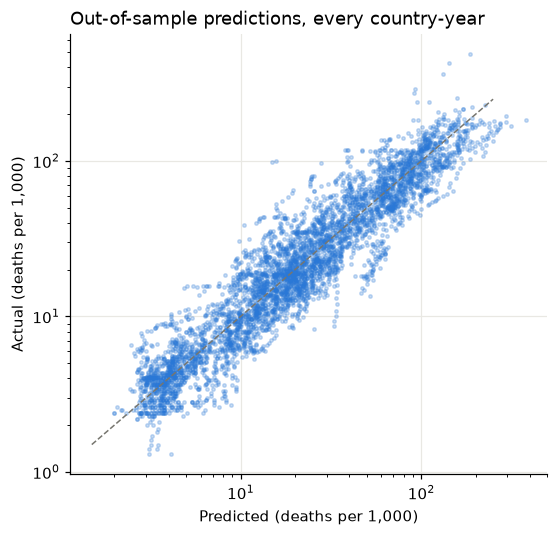

In [10]:
pred = oof["Gradient boosting, monotonic"]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(np.exp(pred), np.exp(y), s=5, alpha=0.25, color=BLUE)
ax.plot([1.5, 250], [1.5, 250], color=GREY, ls="--", lw=1)
ax.set(xscale="log", yscale="log", xlabel="Predicted (deaths per 1,000)", ylabel="Actual (deaths per 1,000)")
ax.set_title("Out-of-sample predictions, every country-year", loc="left")
plt.show()

## 6. Which factors matter most?

The final model is fitted on all countries. SHAP values show how much each indicator moves the prediction on average.

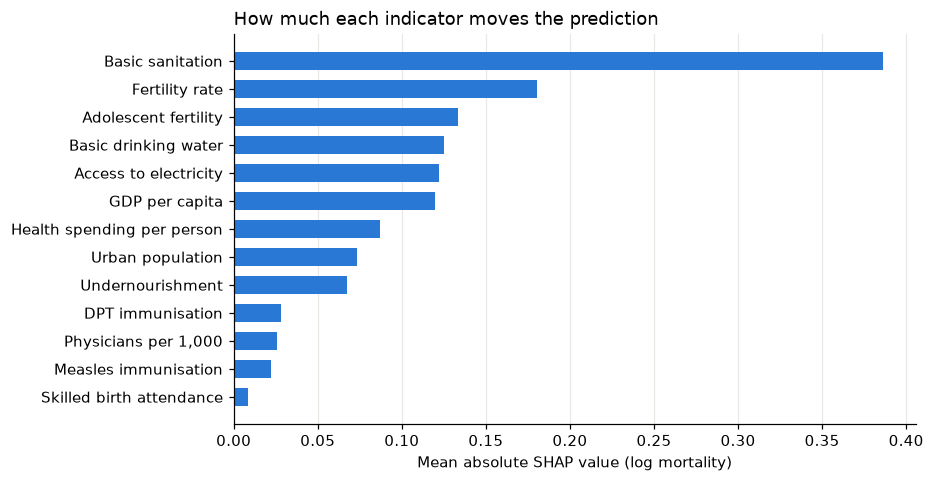

In [11]:
final = make_gbm().fit(X, y)
contrib = final.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values()
LABELS = {"log_gdp": "GDP per capita", "log_health_spending": "Health spending per person", "dpt_immunisation": "DPT immunisation",
          "measles_immunisation": "Measles immunisation", "basic_water": "Basic drinking water", "basic_sanitation": "Basic sanitation",
          "electricity": "Access to electricity", "urban": "Urban population", "fertility": "Fertility rate",
          "adolescent_fertility": "Adolescent fertility", "undernourishment": "Undernourishment",
          "skilled_birth_attendance": "Skilled birth attendance", "physicians": "Physicians per 1,000"}
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([LABELS[f] for f in importance.index], importance.values, color=BLUE, height=0.65)
ax.set_xlabel("Mean absolute SHAP value (log mortality)")
ax.set_title("How much each indicator moves the prediction", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

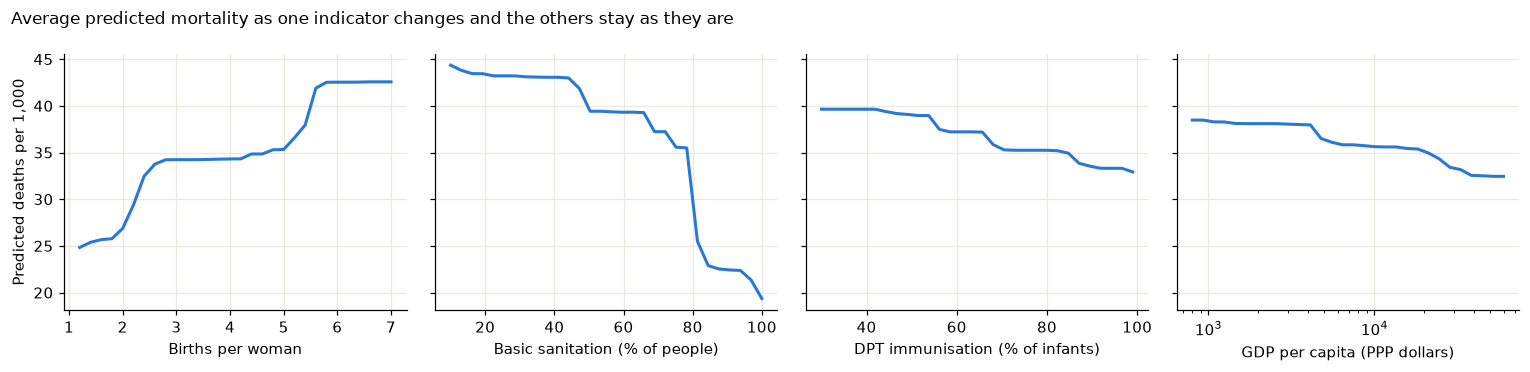

In [12]:
def dependence(feature, grid):
    base = X.copy()
    values = []
    for v in grid:
        base[feature] = v
        values.append(float(np.exp(final.predict(base)).mean()))
    return values


curves = {
    "fertility": np.linspace(1.2, 7, 30),
    "basic_sanitation": np.linspace(10, 100, 30),
    "dpt_immunisation": np.linspace(30, 99, 30),
    "log_gdp": np.log(np.geomspace(800, 60000, 30)),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
titles = {"fertility": "Births per woman", "basic_sanitation": "Basic sanitation (% of people)", "dpt_immunisation": "DPT immunisation (% of infants)", "log_gdp": "GDP per capita (PPP dollars)"}
curve_values = {}
for ax, (feature, grid) in zip(axes, curves.items()):
    curve_values[feature] = dependence(feature, grid)
    x_values = np.exp(grid) if feature == "log_gdp" else grid
    ax.plot(x_values, curve_values[feature], color=BLUE, lw=2)
    if feature == "log_gdp":
        ax.set_xscale("log")
    ax.set_xlabel(titles[feature])
axes[0].set_ylabel("Predicted deaths per 1,000")
fig.suptitle("Average predicted mortality as one indicator changes and the others stay as they are", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Reading these charts carefully.** The importance ranking and the curves describe **associations across countries**, not the effect of an intervention. Basic sanitation ranks first and the fertility measures next. Fertility ranks high partly because it stands in for many things the data does not measure directly: women's education, access to family planning, birth spacing, and the general development of the health system. Lowering the fertility number in the model is not the same as running a programme.

What the analysis does support:

* Child survival is not just a matter of income. Sanitation, immunisation and fertility-related factors carry weight after income is accounted for.
* The relationships flatten at the top: the last few points of immunisation coverage or sanitation access are associated with smaller changes than the first, because countries at that level already have low mortality.

## 7. Countries doing better or worse than expected

The out-of-sample prediction for each country says what its mortality "should" be given its income, services and demographics, based on what was learned from *other* countries. Comparing that with reality identifies:

* **Positive outliers**: mortality well below what their circumstances predict. These countries are worth studying for what they do differently.
* **Negative outliers**: mortality well above the prediction. Something not captured by these indicators, often conflict or a weak health system, is costing lives.

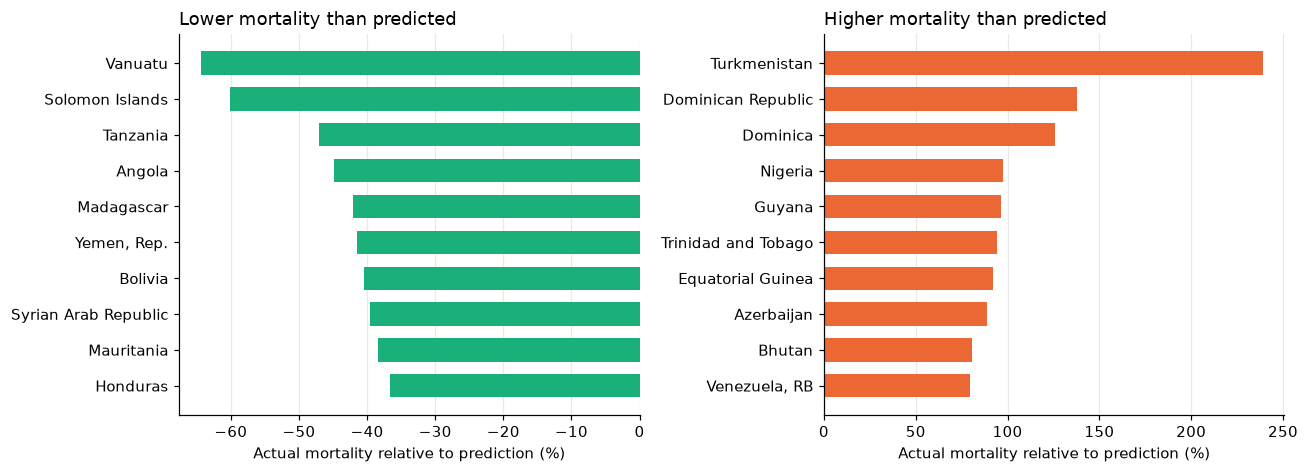

Better than predicted:
             country  actual  predicted
             Vanuatu    17.7       49.7
     Solomon Islands    21.3       53.3
            Tanzania    40.2       75.9
              Angola    51.8       93.8
          Madagascar    64.1      110.7
         Yemen, Rep.    40.9       69.9
             Bolivia    17.4       29.2
Syrian Arab Republic    20.3       33.6
          Mauritania    39.4       64.0
            Honduras    16.0       25.3

Worse than predicted:
            country  actual  predicted
       Turkmenistan    41.1       12.1
 Dominican Republic    32.2       13.5
           Dominica    34.9       15.4
            Nigeria   117.0       59.3
             Guyana    26.9       13.7
Trinidad and Tobago    19.8       10.2
  Equatorial Guinea    72.8       37.9
         Azerbaijan    19.6       10.4
             Bhutan    19.1       10.6
      Venezuela, RB    24.2       13.5


In [13]:
model_data["predicted"] = np.exp(pred)
recent = model_data[model_data["year"] >= LAST - 4].groupby(["iso3", "country", "region"]).agg(actual=("u5mr", "mean"), predicted=("predicted", "mean"), deaths=("u5_deaths", "mean")).reset_index()
recent["ratio"] = recent["actual"] / recent["predicted"]
considered = recent[recent["actual"] >= 15]
better = considered.nsmallest(10, "ratio")
worse = considered.nlargest(10, "ratio")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, table, title, color in [(axes[0], better, "Lower mortality than predicted", AQUA), (axes[1], worse, "Higher mortality than predicted", ORANGE)]:
    table = table.iloc[::-1]
    ax.barh(table["country"], (table["ratio"] - 1) * 100, color=color, height=0.65)
    ax.set_xlabel("Actual mortality relative to prediction (%)")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print("Better than predicted:")
print(better[["country", "actual", "predicted"]].round(1).to_string(index=False))
print()
print("Worse than predicted:")
print(worse[["country", "actual", "predicted"]].round(1).to_string(index=False))

Only countries with mortality of at least 15 per 1,000 are compared, since small absolute differences produce large ratios at very low rates.

These lists need careful reading. A gap between actual and predicted can mean a country really is doing something the indicators do not capture, such as strong community health programmes. It can also reflect data quality: in countries without complete birth and death registration, including several affected by conflict, the mortality figures are themselves model-based estimates with wide uncertainty. Nigeria stands out on the right-hand list because it combines the highest death toll in the world with mortality about twice what its income and services would predict. The lists are a starting point for qualitative work, not a ranking.

## 8. Export for the live dashboard

The dashboard runs the model in the browser so a user can pick a country and change its indicators. The trees are exported to JSON and re-scored in pure Python to confirm they match XGBoost.

In [14]:
def export_trees(model, columns, sample):
    booster = model.get_booster()
    index = {name: i for i, name in enumerate(columns)}
    trees = []
    for dump in booster.get_dump(dump_format="json"):
        nodes = {}
        stack = [json.loads(dump.replace(": -inf", ": -1e38").replace(": inf", ": 1e38"))]
        while stack:
            node = stack.pop()
            nodes[node["nodeid"]] = node
            stack.extend(node.get("children", []))
        size = max(nodes) + 1
        tree = {"f": [-1] * size, "t": [0] * size, "y": [0] * size, "n": [0] * size, "m": [0] * size, "v": [0] * size}
        for i, node in nodes.items():
            if "leaf" in node:
                tree["v"][i] = round(node["leaf"], 6)
            else:
                tree["f"][i] = index[node["split"]]
                tree["t"][i] = float(np.float32(node["split_condition"]))
                tree["y"][i], tree["n"][i], tree["m"][i] = node["yes"], node["no"], node["missing"]
        trees.append(tree)

    def raw_sum(row):
        total = 0.0
        for tree in trees:
            i = 0
            while tree["f"][i] != -1:
                value = row[tree["f"][i]]
                i = tree["m"][i] if np.isnan(value) else (tree["y"][i] if value < tree["t"][i] else tree["n"][i])
            total += tree["v"][i]
        return total

    values = sample.to_numpy(dtype=np.float32).astype(float)
    sums = np.array([raw_sum(row) for row in values])
    margins = booster.predict(xgb.DMatrix(sample), output_margin=True)
    base = float(np.mean(margins - sums))
    assert np.max(np.abs(sums + base - margins)) < 1e-4, "exported trees do not reproduce the model"
    return {"features": list(columns), "base": round(base, 6), "trees": trees, "objective": "regression"}


exported = export_trees(final, FEATURES, X.sample(500, random_state=SEED))
print("Exported", len(exported["trees"]), "trees. Predictions match XGBoost on 500 country-years.")

Exported 400 trees. Predictions match XGBoost on 500 country-years.


In [15]:
def none_if_nan(v, digits=3):
    return None if pd.isna(v) else round(float(v), digits)


filled = model_data.sort_values(["iso3", "year"]).copy()
filled[FEATURES] = filled.groupby("iso3")[FEATURES].ffill(limit=5)
profile_rows = filled.groupby("iso3").tail(1)
profiles = [{"iso3": r["iso3"], "country": r["country"], "year": int(r["year"]), "u5mr": none_if_nan(r["u5mr"], 1),
             "features": {f: none_if_nan(r[f]) for f in FEATURES}} for _, r in profile_rows.iterrows()]

map_years = list(range(2000, LAST + 1))
map_data = panel.pivot(index="iso3", columns="year", values="u5mr").reindex(columns=map_years)
names = panel.drop_duplicates("iso3").set_index("iso3")["country"]

summary = {
    "last_year": LAST,
    "world": [{"year": int(y), "u5mr": none_if_nan(r["u5mr"], 1), "deaths": none_if_nan(r["u5_deaths"], 0)} for y, r in w.iterrows()],
    "regions": json.loads(by_region.reset_index().to_json(orient="records")),
    "top_countries": json.loads(top_countries.to_json(orient="records")),
    "top10_share": float(top_countries["u5_deaths"].sum() / latest["u5_deaths"].sum()),
    "sdg": json.loads(sdg.to_json(orient="records")),
    "sdg_counts": {k: int(v) for k, v in counts.items()},
    "excess_deaths_2030": float(off["excess_deaths_2030"].sum()),
    "sensitivity": json.loads(sensitivity.reset_index().to_json(orient="records")),
    "borderline_count": int(sdg["borderline"].sum()),
    "metrics": json.loads(metrics.reset_index().to_json(orient="records")),
    "importance": [{"feature": LABELS[k], "value": float(v)} for k, v in importance.sort_values(ascending=False).items()],
    "curves": {f: {"x": [float(np.exp(v)) if f == "log_gdp" else float(v) for v in grid], "y": curve_values[f]} for f, grid in curves.items()},
    "better": json.loads(better[["country", "actual", "predicted", "ratio"]].to_json(orient="records")),
    "worse": json.loads(worse[["country", "actual", "predicted", "ratio"]].to_json(orient="records")),
    "map": {"years": map_years, "iso3": list(map_data.index), "names": [names[i] for i in map_data.index],
            "values": [[none_if_nan(v, 1) for v in row] for row in map_data.values]},
    "profiles": profiles,
    "labels": LABELS,
    "ranges": {f: [none_if_nan(X[f].quantile(0.01)), none_if_nan(X[f].quantile(0.99))] for f in FEATURES},
    "countries": int(panel["iso3"].nunique()),
    "country_years": int(len(model_data)),
}
(APP / "model.json").write_text(json.dumps(exported, separators=(",", ":")))
(APP / "summary.json").write_text(json.dumps(summary, separators=(",", ":")))
print("model.json", round((APP / "model.json").stat().st_size / 1024), "KB; summary.json", round((APP / "summary.json").stat().st_size / 1024), "KB")

model.json 256 KB; summary.json 180 KB


## 9. Conclusions

* Under-five mortality has halved since 2000, from 77 to 37 deaths per 1,000 live births, and annual deaths have fallen from about 10 million to under 5 million.
* Progress is uneven. On current trends 61 countries will miss the 2030 target of 25 per 1,000, and 44 of them are in Sub-Saharan Africa. The typical off-track country is reducing mortality at 2.6 percent a year and would need about 11 percent a year to get there.
* Ten countries account for 60 percent of all under-five deaths. Nigeria has both the largest number of deaths and almost no measured improvement over the last decade.
* Income explains much of the difference between countries, but not all of it. A model that adds immunisation, water, sanitation, fertility, nutrition and health system indicators predicts mortality in unseen countries considerably better than income alone (R squared 0.89 against 0.72).
* Some countries have much lower mortality than their circumstances predict, and some much higher. Those gaps are leads for further investigation.

**Limitations**

* The model describes associations across countries. It does not show that changing one indicator would cause mortality to change by the amount on the curve. The dashboard's what-if tool should be read as "countries that look like this tend to have mortality of about this", not as a forecast of a policy's effect.
* Mortality estimates for countries without complete vital registration are themselves modelled by the UN, with wide uncertainty.
* National averages hide large differences within countries, between regions and between rich and poor households.
* The projection to 2030 is a simple continuation of the last ten years and assumes the number of births stays constant. It is a single number with no uncertainty interval. Changing the trend window to 5 or 15 years moves only one country across the line each time, but the countries flagged as too close to call could plausibly land on either side.

**Next steps.** Repeat the analysis at subnational level with DHS survey data, separate neonatal from post-neonatal mortality since their causes differ, and use within-country changes over time (fixed effects) to get closer to causal estimates.